# Digital Image Processing Lab - Lab Task 04
## Geometric Transformations with Custom Inputs

| | |
|---|---|
| **Name** | Syed Muhammad Hassan Gillani |
| **Roll No** | 2024-SE-42 |
| **Semester** | 5th (Fifth), Software Engineering, Session 2024-28 |
| **Lab Instructor** | Engr. Fahad Nisar |
| **University** | The University of Azad Jammu and Kashmir, Department of Software Engineering |
| **Assigned / Due** | November 05, 2026 / November 12, 2026, 11:59 PM |

### Objective
Build one reusable function `transform(image, operation, **params)` that performs **scaling, cropping, flipping, translation and rotation** using *custom values*, validates every input, and returns the transformed image.

### Conventions declared for the whole notebook
* **Colour handling:** OpenCV reads images as BGR; the image is converted **once** to **RGB** in `load_image`. Every operation and every display uses RGB `uint8` arrays.
* **Image coordinates:** a point is `(x, y)` = `(column, row)`, origin at the **top-left**, `y` grows **downward**. NumPy indexing is `img[row, column]` = `img[y, x]`.
* **Exposed background:** areas uncovered by translation/rotation are filled with **black (0)**.
* **Rotation:** about the image centre; a **positive angle rotates counter-clockwise** on screen.
* **Maximum output size:** **4000 px per side** and **16,000,000 px in total**; anything larger is rejected.
* **Where the code lives:** `transforms.py` (helper source file) holds `transform` and the validators; this notebook imports it, runs the demonstrations and shows the results.

## 0. Setup

In [1]:
import os, inspect, time
import numpy as np
import cv2
import matplotlib.pyplot as plt

import transforms
from transforms import (transform, load_image, TransformError, ScriptedInput, run_interactive,
                        translation_matrix, rotation_matrix, OPERATIONS, INTERPOLATIONS,
                        FLIP_DIRECTIONS, MAX_SIDE, MAX_PIXELS)

# Set INTERACTIVE = True (and re-run the "live prompt" cell in section 3) to type your own values.
# With False, the notebook replays recorded answers so it runs top-to-bottom without stopping.
INTERACTIVE = False

IMAGE_PATH = "input/sample_image.png"
OUT_DIR = "outputs"
CMP_DIR = os.path.join(OUT_DIR, "comparisons")
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(CMP_DIR, exist_ok=True)

print("OpenCV", cv2.__version__, "| NumPy", np.__version__)
print(f"Declared output limit: {MAX_SIDE} px per side, {MAX_PIXELS:,} px total")

OpenCV 5.0.0 | NumPy 2.5.4
Declared output limit: 4000 px per side, 16,000,000 px total


## 1. Load and validate the input image
`load_image` checks that the file **exists**, **decodes**, and has **non-zero dimensions** before returning an RGB array. The original is then locked (`writeable = False`) and a backup copy is kept so we can prove at the end that it was never modified.

File           : input/sample_image.png
Width  (x)     : 600 px
Height (y)     : 400 px
Array shape    : (400, 600, 3)   -> (rows=height, columns=width, channels)
dtype / colour : uint8 / RGB (converted once from OpenCV BGR)


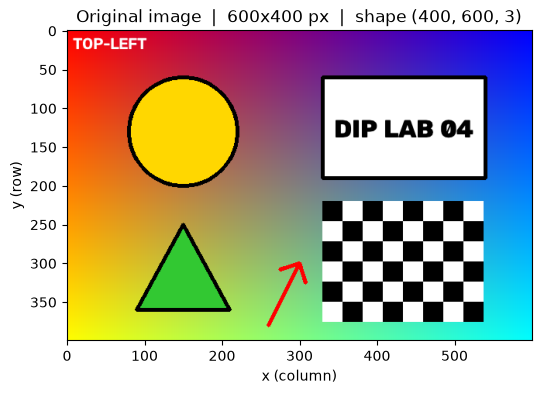

In [2]:
original = load_image(IMAGE_PATH)
original_backup = original.copy()      # used for the "original unchanged" proof at the end
original.flags.writeable = False       # any accidental in-place edit would raise an error

h0, w0 = original.shape[:2]
print(f"File           : {IMAGE_PATH}")
print(f"Width  (x)     : {w0} px")
print(f"Height (y)     : {h0} px")
print(f"Array shape    : {original.shape}   -> (rows=height, columns=width, channels)")
print(f"dtype / colour : {original.dtype} / RGB (converted once from OpenCV BGR)")

plt.figure(figsize=(6, 4.2))
plt.imshow(original); plt.title(f"Original image  |  {w0}x{h0} px  |  shape {original.shape}")
plt.xlabel("x (column)"); plt.ylabel("y (row)"); plt.show()

**Validation of the image itself** - a missing file, a file that is not an image, and an empty array are all rejected with clear messages (no crash):

In [3]:
with open("input/not_an_image.png", "w") as f:        # exists, but contains text, not image data
    f.write("this is not image data")

for label, action in [
    ("missing file",          lambda: load_image("input/does_not_exist.png")),
    ("undecodable file",      lambda: load_image("input/not_an_image.png")),
    ("directory, not a file", lambda: load_image("input")),
    ("zero-height array",     lambda: transform(np.zeros((0, 5, 3), np.uint8), "flip", direction="both")),
    ("float image array",     lambda: transform(np.zeros((4, 4, 3), float), "flip", direction="both")),
]:
    try:
        action(); print(f"{label:22s}: NOT rejected (unexpected)")
    except TransformError as e:
        print(f"{label:22s}: REJECTED -> {e}")

os.remove("input/not_an_image.png")                   # clean up the temporary file

missing file          : REJECTED -> File not found: 'input/does_not_exist.png'
undecodable file      : REJECTED -> File exists but could not be decoded as an image: 'input/not_an_image.png'
directory, not a file : REJECTED -> Not a file: 'input'
zero-height array     : REJECTED -> Image has an empty dimension: (0, 5, 3).
float image array     : REJECTED -> image must be uint8, got float64.


## 2. The reusable `transform` function
One entry point for all five operations. The operation name and its parameters are **arguments** - nothing is hard-coded inside the function.

| Operation | Parameters | Rule enforced inside `transform` |
|---|---|---|
| `scale` | `sx`, `sy`, `interpolation` | finite and > 0; output ints >= 1 and within the size limit; interpolation in nearest / bilinear / bicubic / lanczos |
| `crop` | `left`, `top`, `right`, `bottom` | integers; `0 <= left < right <= W`, `0 <= top < bottom <= H` (right/bottom exclusive) |
| `flip` | `direction` | horizontal / vertical / both |
| `translate` | `tx`, `ty` | any finite number (positive, negative, zero); canvas size unchanged |
| `rotate` | `angle`, `expand` | any finite angle (incl. 0 and negative); `expand` must be True/False |

It also rejects an unknown operation, missing parameters, unexpected extra parameters, NaN/infinity, non-numeric values and empty/oversized outputs.

In [4]:
print(inspect.getsource(transform))
print("Supported operations and required parameters:")
for op, req in OPERATIONS.items():
    print(f"  {op:10s} -> {', '.join(req)}")

def transform(image, operation, **params):
    """
    Single reusable entry point.

    operation / required parameters
      'scale'     sx, sy (finite > 0), interpolation in nearest|bilinear|bicubic|lanczos
      'crop'      left, top, right, bottom (ints; 0<=left<right<=W, 0<=top<bottom<=H; right/bottom exclusive)
      'flip'      direction in horizontal|vertical|both
      'translate' tx, ty (finite numbers, may be negative or zero), canvas size unchanged
      'rotate'    angle (finite degrees, + = counter-clockwise), expand (bool)

    Returns a NEW array; the input image is never modified.
    Raises TransformError for anything invalid (unknown operation, missing/extra
    parameters, bad values, empty or oversized output).
    """
    _check_image(image)
    if not isinstance(operation, str):
        raise TransformError(f"Operation must be a string, got {type(operation).__name__}.")
    op = operation.strip().lower()
    if op not in OPERATIONS:
        raise TransformError(

## 3. User-selected operation and custom parameters
`run_interactive` asks for the operation and for each parameter with `input()`, parses the text, and passes the values to `transform`. A bad entry prints a message and the question is **asked again** - there is no crash and no silent default.

For a reproducible notebook the answers below are **replayed from a script** (`ScriptedInput`), including deliberate mistakes so the correction behaviour is visible. Each line after a prompt is the typed answer.

In [5]:
RESULTS = []   # every saved transformed image is logged here for the final summary

def fmt_params(p):
    return ", ".join(f"{k}={v}" for k, v in p.items())

def save_result(name, img):
    path = os.path.join(OUT_DIR, f"{name}.png")
    cv2.imwrite(path, cv2.cvtColor(img, cv2.COLOR_RGB2BGR))      # back to BGR only for writing
    return path

def show_row(items, fname=None, width_per=4.2):
    """items = [(image, title), ...] drawn side by side with pixel-coordinate axes."""
    fig, axes = plt.subplots(1, len(items), figsize=(width_per * len(items), 4.0))
    axes = np.atleast_1d(axes)
    for ax, (im, title) in zip(axes, items):
        ax.imshow(im); ax.set_title(title, fontsize=9)
        ax.tick_params(labelsize=7)
    plt.tight_layout()
    if fname: fig.savefig(os.path.join(CMP_DIR, fname + ".png"), dpi=110, bbox_inches="tight")
    plt.show()

def label_for(op, params, img):
    return f"{op}: {fmt_params(params)}\noutput {img.shape[1]}x{img.shape[0]} px"

def interactive_demo(answers, name):
    if answers is None and not INTERACTIVE:
        print("Live mode is off. Set INTERACTIVE = True in the setup cell and run this cell again.")
        return
    feed = input if INTERACTIVE and answers is None else ScriptedInput(answers)
    out = run_interactive(original, feed)
    if out is None:
        return
    op, params, res = out
    path = save_result(f"interactive_{name}", res)
    RESULTS.append((f"interactive_{name}", op, fmt_params(params), f"{res.shape[1]}x{res.shape[0]}", path))
    print(f"\n-> transform OK: {op} {params} -> {res.shape[1]}x{res.shape[0]}  saved {path}")
    show_row([(original, f"Original\n{w0}x{h0} px"), (res, label_for(op, params, res))], f"interactive_{name}")

**3a. Scaling** - typo operation, non-numeric `sx`, `nan`, then valid values; unsupported interpolation `cubic` corrected to `bicubic`:

Operation (scale/crop/flip/translate/rotate, or q to quit): zoom
[!] Unknown operation 'zoom'. Supported: scale, crop, flip, translate, rotate.
Operation (scale/crop/flip/translate/rotate, or q to quit): scale
  Horizontal scale factor sx (> 0): abc
    [!] 'sx': 'abc' is not a number.  (try again)
  Horizontal scale factor sx (> 0): nan
    [!] 'sx': NaN/infinity is not allowed (got 'nan').  (try again)
  Horizontal scale factor sx (> 0): 1.5
  Vertical scale factor sy (> 0): 0.75
  Interpolation (nearest/bilinear/bicubic/lanczos): cubic
    [!] 'interpolation': 'cubic' is not supported. Choose from: nearest, bilinear, bicubic, lanczos.  (try again)
  Interpolation (nearest/bilinear/bicubic/lanczos): bicubic

-> transform OK: scale {'sx': 1.5, 'sy': 0.75, 'interpolation': 'bicubic'} -> 900x300  saved outputs\interactive_scale.png


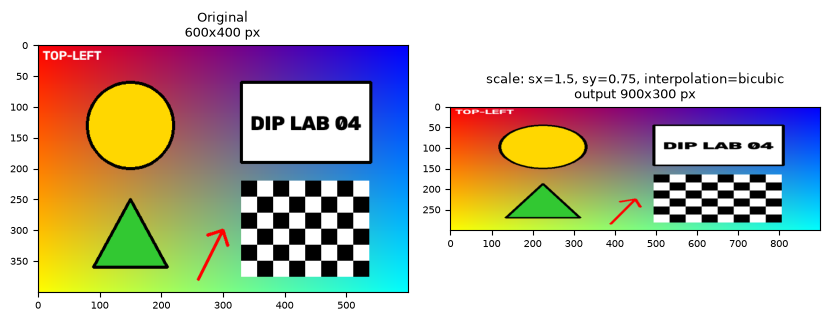

In [6]:
interactive_demo(["zoom", "scale", "abc", "nan", "1.5", "0.75", "cubic", "bicubic"], "scale")

**3b. Cropping** - a non-integer `left` (10.5) is corrected, then `right (80) <= left (100)` is rejected by `transform` and the whole region is re-entered:

Operation (scale/crop/flip/translate/rotate, or q to quit): crop
  Left x (int): 10.5
    [!] 'left': '10.5' is not a whole number (integer required).  (try again)
  Left x (int): 100
  Top y (int): 50
  Right x, exclusive (int): 80
  Bottom y, exclusive (int): 250
[!] Invalid horizontal range: need 0 <= left < right <= width (600); got left=100, right=80.
    Please re-enter the parameters.
Operation (scale/crop/flip/translate/rotate, or q to quit): crop
  Left x (int): 100
  Top y (int): 50
  Right x, exclusive (int): 400
  Bottom y, exclusive (int): 250

-> transform OK: crop {'left': 100, 'top': 50, 'right': 400, 'bottom': 250} -> 300x200  saved outputs\interactive_crop.png


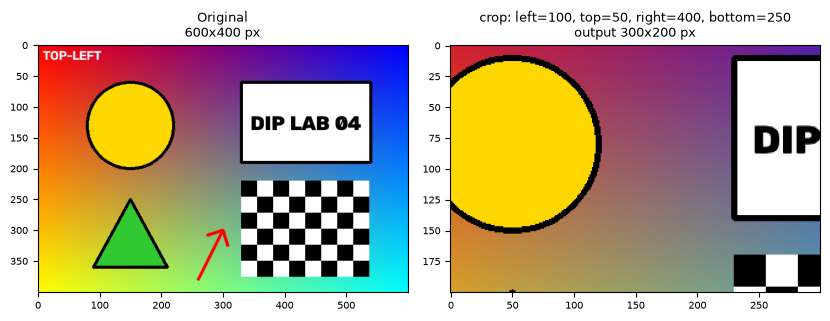

In [7]:
interactive_demo(["crop", "10.5", "100", "50", "80", "250",
                  "crop", "100", "50", "400", "250"], "crop")

**3c. Flipping** - unsupported direction `diagonal` is rejected, `both` accepted:

Operation (scale/crop/flip/translate/rotate, or q to quit): flip
  Flip direction (horizontal/vertical/both): diagonal
    [!] 'direction': 'diagonal' is not supported. Choose from: horizontal, vertical, both.  (try again)
  Flip direction (horizontal/vertical/both): both

-> transform OK: flip {'direction': 'both'} -> 600x400  saved outputs\interactive_flip.png


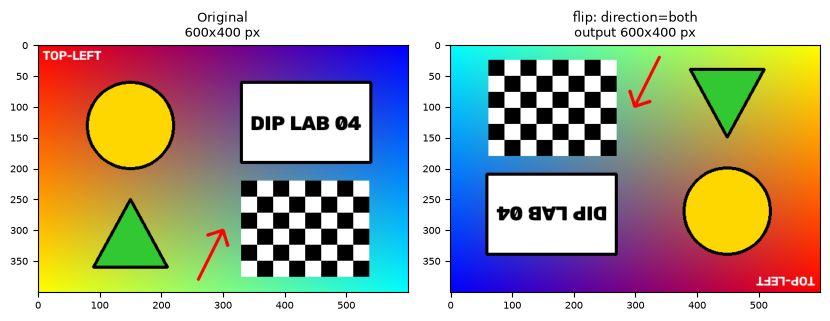

In [8]:
interactive_demo(["flip", "diagonal", "both"], "flip")

**3d. Translation** - negative `tx` is valid; infinite `ty` is rejected, then corrected:

Operation (scale/crop/flip/translate/rotate, or q to quit): translate
  Horizontal offset tx in px (+ = right): -80
  Vertical offset ty in px (+ = down): inf
    [!] 'ty': NaN/infinity is not allowed (got 'inf').  (try again)
  Vertical offset ty in px (+ = down): 40

-> transform OK: translate {'tx': -80.0, 'ty': 40.0} -> 600x400  saved outputs\interactive_translate.png


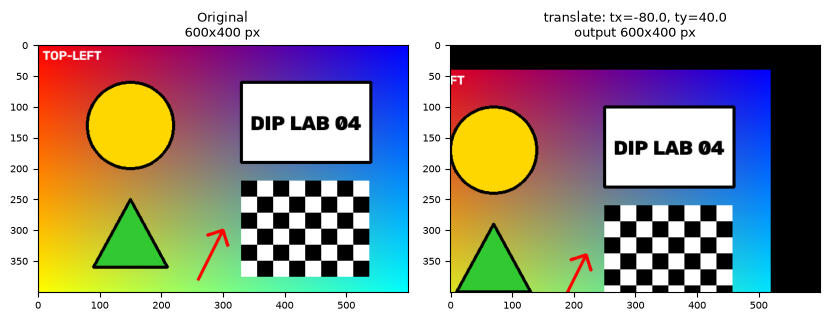

In [9]:
interactive_demo(["translate", "-80", "inf", "40"], "translate")

**3e. Rotation** - non-numeric angle and invalid expand answer are rejected; `-30` degrees with expansion accepted:

Operation (scale/crop/flip/translate/rotate, or q to quit): rotate
  Angle in degrees (+ = counter-clockwise): abc
    [!] 'angle': 'abc' is not a number.  (try again)
  Angle in degrees (+ = counter-clockwise): -30
  Expand canvas to fit? (yes/no): maybe
    [!] 'expand': 'maybe' is not valid. Answer yes or no.  (try again)
  Expand canvas to fit? (yes/no): yes

-> transform OK: rotate {'angle': -30.0, 'expand': True} -> 720x647  saved outputs\interactive_rotate.png


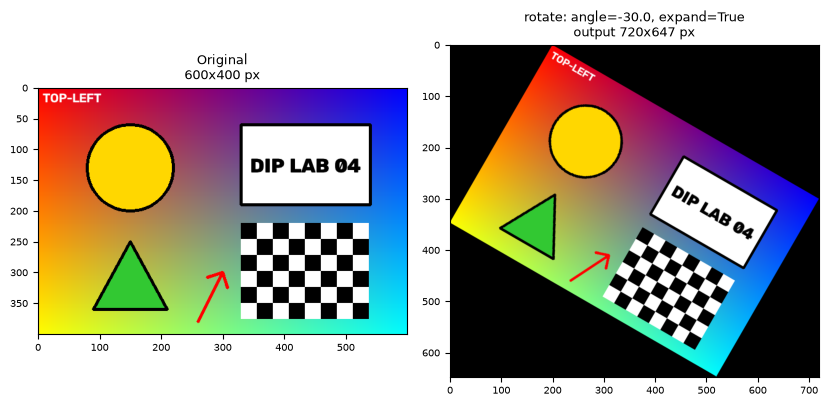

In [10]:
interactive_demo(["rotate", "abc", "-30", "maybe", "yes"], "rotate")

**3f. Live prompt** - set `INTERACTIVE = True` in the setup cell and run this cell to enter your own operation and values:

In [11]:
interactive_demo(None, "user_live")

Live mode is off. Set INTERACTIVE = True in the setup cell and run this cell again.


## 4. Demonstration of every operation with custom values
`demo()` calls `transform` with explicit values, saves the result in `outputs/`, and the figure labels show **operation, parameters and output dimensions**.

In [12]:
def demo(name, op, **params):
    res = transform(original, op, **params)
    path = save_result(name, res)
    RESULTS.append((name, op, fmt_params(params), f"{res.shape[1]}x{res.shape[0]}", path))
    return res

orig_item = (original, f"Original\n{w0}x{h0} px")

### 4.1 Scaling / resizing
Enlargement (2.0 x 2.0), reduction (0.5 x 0.5), **proportional** (equal factors keep the aspect ratio) and **non-proportional** (different factors distort it). Output size = `round(W*sx) x round(H*sy)`.

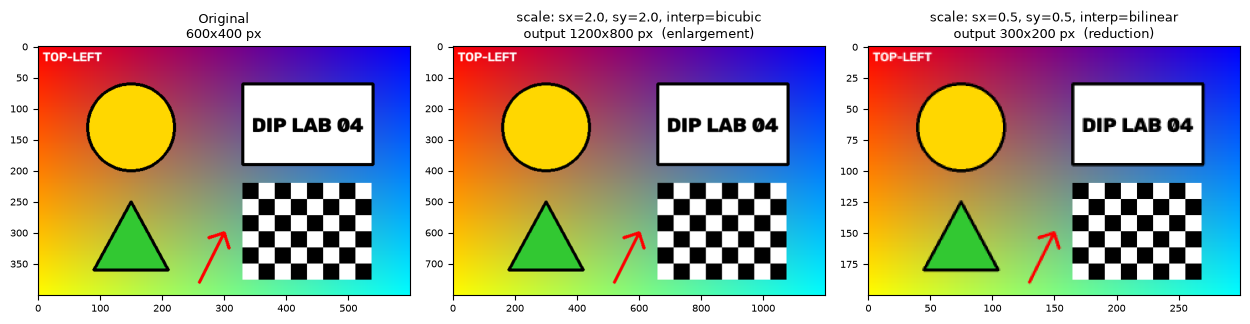

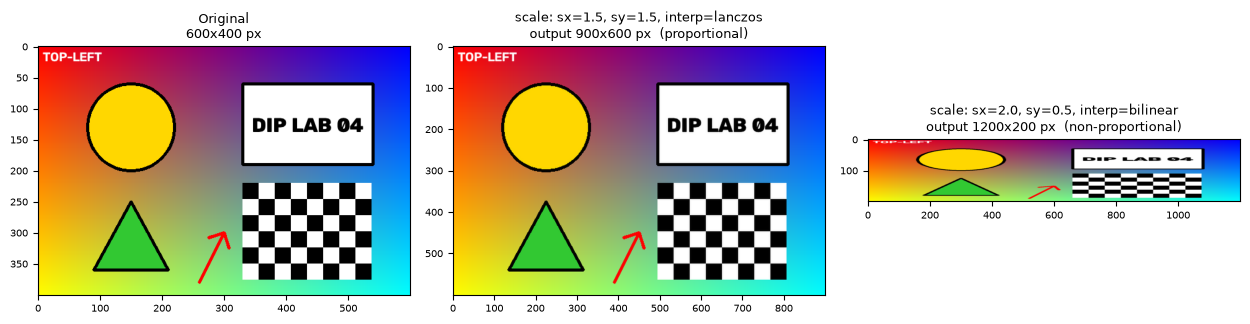

original                   600x400  aspect ratio W/H = 1.500
proportional 1.5x1.5       900x600  aspect ratio W/H = 1.500
non-proportional 2.0x0.5   1200x200  aspect ratio W/H = 6.000


In [13]:
s_up   = demo("scale_enlarge_2.0x2.0_bicubic",   "scale", sx=2.0, sy=2.0, interpolation="bicubic")
s_down = demo("scale_reduce_0.5x0.5_bilinear",   "scale", sx=0.5, sy=0.5, interpolation="bilinear")
s_prop = demo("scale_proportional_1.5x1.5_lanczos", "scale", sx=1.5, sy=1.5, interpolation="lanczos")
s_non  = demo("scale_nonproportional_2.0x0.5_bilinear", "scale", sx=2.0, sy=0.5, interpolation="bilinear")

show_row([orig_item,
          (s_up,   label_for("scale", dict(sx=2.0, sy=2.0, interp="bicubic"), s_up) + "  (enlargement)"),
          (s_down, label_for("scale", dict(sx=0.5, sy=0.5, interp="bilinear"), s_down) + "  (reduction)")],
         "4_1a_scale_enlarge_reduce")
show_row([orig_item,
          (s_prop, label_for("scale", dict(sx=1.5, sy=1.5, interp="lanczos"), s_prop) + "  (proportional)"),
          (s_non,  label_for("scale", dict(sx=2.0, sy=0.5, interp="bilinear"), s_non) + "  (non-proportional)")],
         "4_1b_scale_proportional_vs_non")

for nm, im in [("original", original), ("proportional 1.5x1.5", s_prop), ("non-proportional 2.0x0.5", s_non)]:
    print(f"{nm:26s} {im.shape[1]}x{im.shape[0]}  aspect ratio W/H = {im.shape[1]/im.shape[0]:.3f}")

### 4.2 Cropping
`right` and `bottom` are **exclusive**, so the output size is `(right-left) x (bottom-top)`. Crop 1 selects the yellow circle; crop 2 selects the checkerboard.

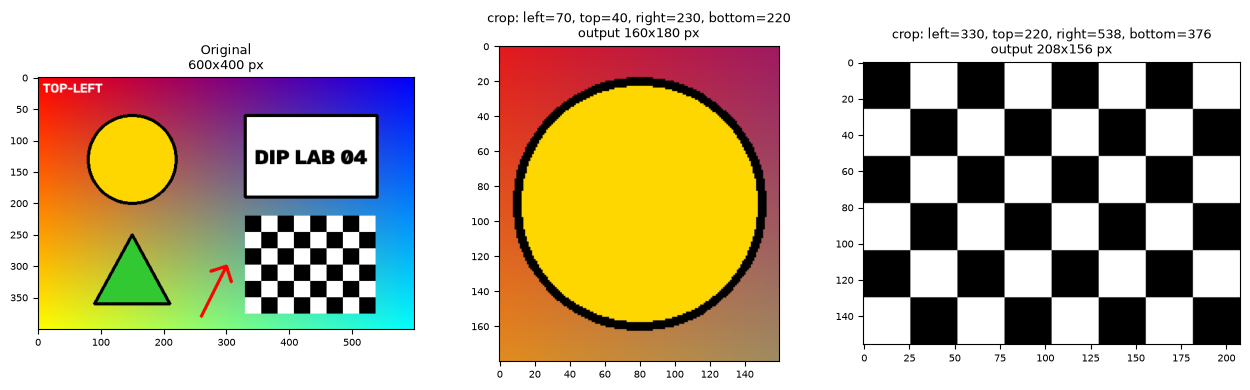

crop 1: (180, 160, 3) == (bottom-top, right-left, 3) = (180, 160, 3)
crop 2: (156, 208, 3) == (bottom-top, right-left, 3) = (156, 208, 3)
crop equals NumPy slice original[40:220, 70:230]: True


In [14]:
c1 = demo("crop_circle_L70_T40_R230_B220",      "crop", left=70, top=40, right=230, bottom=220)
c2 = demo("crop_checkerboard_L330_T220_R538_B376", "crop", left=330, top=220, right=538, bottom=376)
show_row([orig_item,
          (c1, label_for("crop", dict(left=70, top=40, right=230, bottom=220), c1)),
          (c2, label_for("crop", dict(left=330, top=220, right=538, bottom=376), c2))], "4_2_crop")
print("crop 1:", c1.shape, "== (bottom-top, right-left, 3) =", (220-40, 230-70, 3))
print("crop 2:", c2.shape, "== (bottom-top, right-left, 3) =", (376-220, 538-330, 3))
print("crop equals NumPy slice original[40:220, 70:230]:", np.array_equal(c1, original[40:220, 70:230]))

### 4.3 Flipping - horizontal, vertical and both

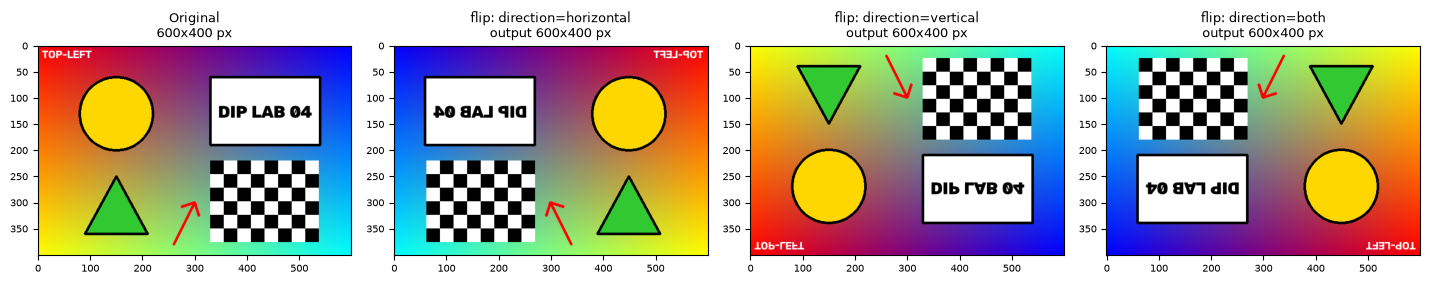

horizontal == original[:, ::-1]   : True
vertical   == original[::-1, :]   : True
both       == original[::-1, ::-1]: True


In [15]:
f_h = demo("flip_horizontal", "flip", direction="horizontal")
f_v = demo("flip_vertical",   "flip", direction="vertical")
f_b = demo("flip_both",       "flip", direction="both")
show_row([orig_item,
          (f_h, label_for("flip", dict(direction="horizontal"), f_h)),
          (f_v, label_for("flip", dict(direction="vertical"), f_v)),
          (f_b, label_for("flip", dict(direction="both"), f_b))], "4_3_flip", width_per=3.6)
print("horizontal == original[:, ::-1]   :", np.array_equal(f_h, original[:, ::-1]))
print("vertical   == original[::-1, :]   :", np.array_equal(f_v, original[::-1, :]))
print("both       == original[::-1, ::-1]:", np.array_equal(f_b, original[::-1, ::-1]))

### 4.4 Translation
Shifts in **opposite directions**: `(tx=+120, ty=+60)` moves content right and down; `(tx=-150, ty=-80)` moves it left and up. The canvas stays `600x400`, so content that leaves the canvas is **clipped** and the side that is uncovered shows the **black background**.

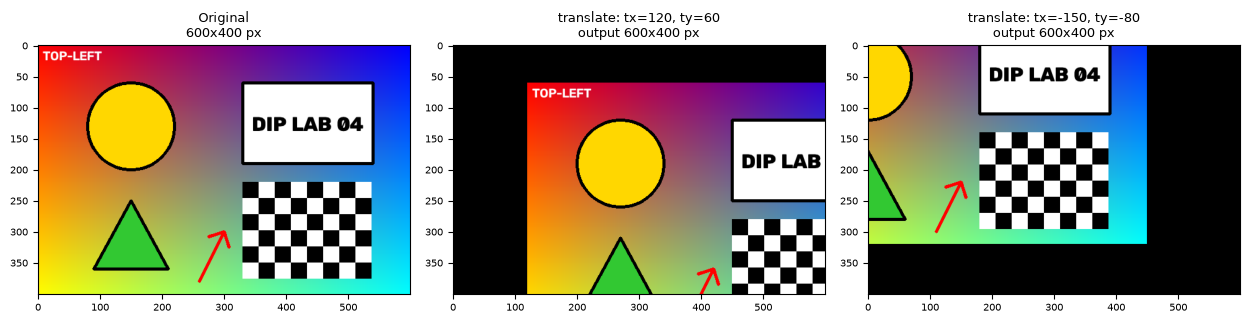

tx=+120, ty=+60: 163,200 of 240,000 original pixels stay visible; 76,800 (32.0%) are clipped, and the same number of canvas pixels are exposed as black.
tx=-150, ty=-80: 144,000 of 240,000 original pixels stay visible; 96,000 (40.0%) are clipped, and the same number of canvas pixels are exposed as black.
black pixels in translate(+120,+60) image: 92587 (includes any naturally black pixels of the picture)


In [16]:
t_pos = demo("translate_tx+120_ty+60",  "translate", tx=120, ty=60)
t_neg = demo("translate_tx-150_ty-80",  "translate", tx=-150, ty=-80)
show_row([orig_item,
          (t_pos, label_for("translate", dict(tx=120, ty=60), t_pos)),
          (t_neg, label_for("translate", dict(tx=-150, ty=-80), t_neg))], "4_4_translate")

def clipping_report(tx, ty):
    vis_w, vis_h = max(0, w0 - abs(tx)), max(0, h0 - abs(ty))
    kept = vis_w * vis_h
    return kept, w0 * h0 - kept

for tx, ty in [(120, 60), (-150, -80)]:
    kept, lost = clipping_report(tx, ty)
    print(f"tx={tx:+d}, ty={ty:+d}: {kept:,} of {w0*h0:,} original pixels stay visible; "
          f"{lost:,} ({100*lost/(w0*h0):.1f}%) are clipped, and the same number of canvas pixels are exposed as black.")
exposed = np.all(t_pos == 0, axis=2)
print("black pixels in translate(+120,+60) image:", int(exposed.sum()), "(includes any naturally black pixels of the picture)")

### 4.5 Rotation
Angles `+30`, `-45` (negative), `+90` and `-30`, with and without canvas expansion. **Positive = counter-clockwise.** The red arrow in the original points up-right; after `+30` it turns counter-clockwise to point straight up, and after `-45` it turns clockwise to point right.
Without expansion the canvas stays `600x400` (corners are clipped); with expansion the canvas grows to `W' = W|cos a| + H|sin a|`, `H' = W|sin a| + H|cos a|`.

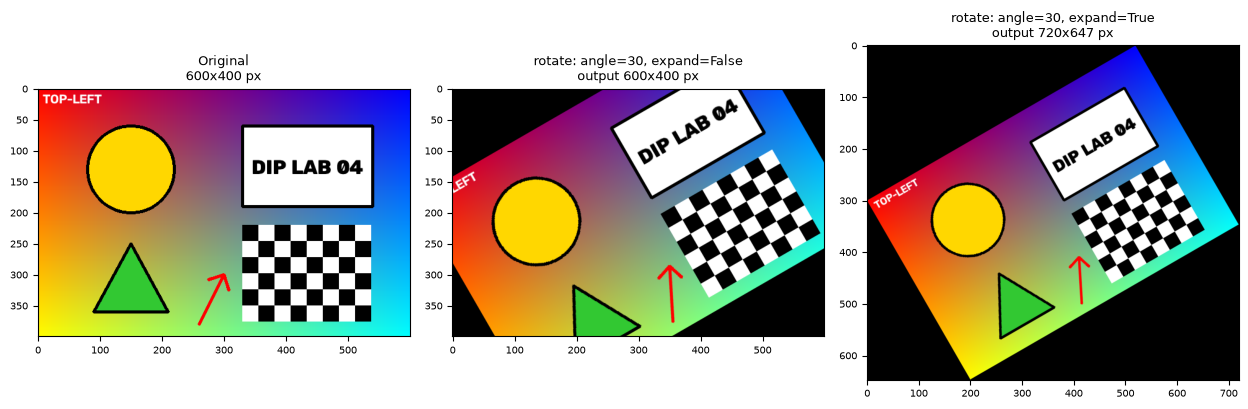

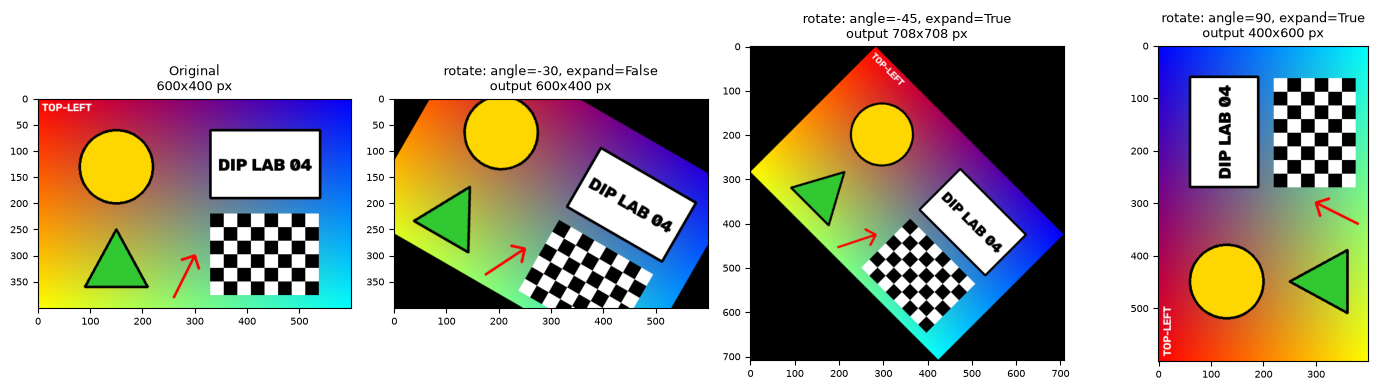

angle +30: formula -> 720x647
angle -45: formula -> 708x708
angle +90: formula -> 400x600
measured: +30 -> 720 x 647 | -45 -> 708 x 708 | +90 -> 400 x 600
rotate(+90, expand) equals np.rot90(original, 1) (counter-clockwise): True


In [17]:
r_p30   = demo("rotate_+30_noexpand", "rotate", angle=30,  expand=False)
r_p30e  = demo("rotate_+30_expand",   "rotate", angle=30,  expand=True)
r_n45e  = demo("rotate_-45_expand",   "rotate", angle=-45, expand=True)
r_p90e  = demo("rotate_+90_expand",   "rotate", angle=90,  expand=True)
r_n30   = demo("rotate_-30_noexpand", "rotate", angle=-30, expand=False)

show_row([orig_item,
          (r_p30,  label_for("rotate", dict(angle=30, expand=False), r_p30)),
          (r_p30e, label_for("rotate", dict(angle=30, expand=True), r_p30e))], "4_5a_rotate_positive")
show_row([orig_item,
          (r_n30,  label_for("rotate", dict(angle=-30, expand=False), r_n30)),
          (r_n45e, label_for("rotate", dict(angle=-45, expand=True), r_n45e)),
          (r_p90e, label_for("rotate", dict(angle=90, expand=True), r_p90e))], "4_5b_rotate_negative_and_90", width_per=3.6)

import math
for a in (30, -45, 90):
    c, s = abs(math.cos(math.radians(a))), abs(math.sin(math.radians(a)))
    print(f"angle {a:+d}: formula -> {math.ceil(w0*c + h0*s - 1e-9)}x{math.ceil(w0*s + h0*c - 1e-9)}")
print("measured: +30 ->", r_p30e.shape[1], "x", r_p30e.shape[0], "| -45 ->", r_n45e.shape[1], "x", r_n45e.shape[0],
      "| +90 ->", r_p90e.shape[1], "x", r_p90e.shape[0])
print("rotate(+90, expand) equals np.rot90(original, 1) (counter-clockwise):", np.array_equal(r_p90e, np.rot90(original, 1)))

### 4.6 Affine matrices behind translation and rotation
Both operations are affine maps `[x', y']^T = M [x, y, 1]^T` with a 2x3 matrix `M`. The matrices used by `transform` can be printed, and applying them directly with `cv2.warpAffine` must reproduce the `transform` output exactly.

In [18]:
np.set_printoptions(precision=4, suppress=True)
M_t = translation_matrix(120, 60)
print("Translation matrix for tx=120, ty=60:\n", M_t)
M_r, ow, oh = rotation_matrix(w0, h0, 30, expand=True)
print("\nRotation matrix for angle=+30 degrees (CCW), expand=True, about the centre:\n", M_r, f"\ncanvas = {ow}x{oh}")

manual_t = cv2.warpAffine(original, M_t, (w0, h0), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
manual_r = cv2.warpAffine(original, M_r, (ow, oh), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
print("\ntranslate: transform() == manual warpAffine:", np.array_equal(manual_t, t_pos))
print("rotate   : transform() == manual warpAffine:", np.array_equal(manual_r, r_p30e))

# the image centre must be a fixed point of the (non-expanded) rotation
M_c, _, _ = rotation_matrix(w0, h0, 30, expand=False)
cx, cy = (w0 - 1) / 2, (h0 - 1) / 2
print("centre", (cx, cy), "maps to", tuple(float(v) for v in np.round(M_c @ [cx, cy, 1], 6)), "-> unchanged, so rotation is about the centre")

Translation matrix for tx=120, ty=60:
 [[  1.   0. 120.]
 [  0.   1.  60.]]

Rotation matrix for angle=+30 degrees (CCW), expand=True, about the centre:
 [[  0.866    0.5      0.3754]
 [ -0.5      0.866  299.9779]] 
canvas = 720x647

translate: transform() == manual warpAffine: True
rotate   : transform() == manual warpAffine: True
centre (299.5, 199.5) maps to (299.5, 199.5) -> unchanged, so rotation is about the centre


## 5. Interpolation comparison on the same enlarged patch
An `80x60` patch containing the arrow head and a checkerboard corner (hard edges, thin diagonal line) is enlarged **8 x 8** with each interpolation method by calling the same `transform`.

patch shape: (60, 80, 3)


nearest   -> 640x480  (1.37 ms)
bilinear  -> 640x480  (0.84 ms)
bicubic   -> 640x480  (4.67 ms)
lanczos   -> 640x480  (10.52 ms)


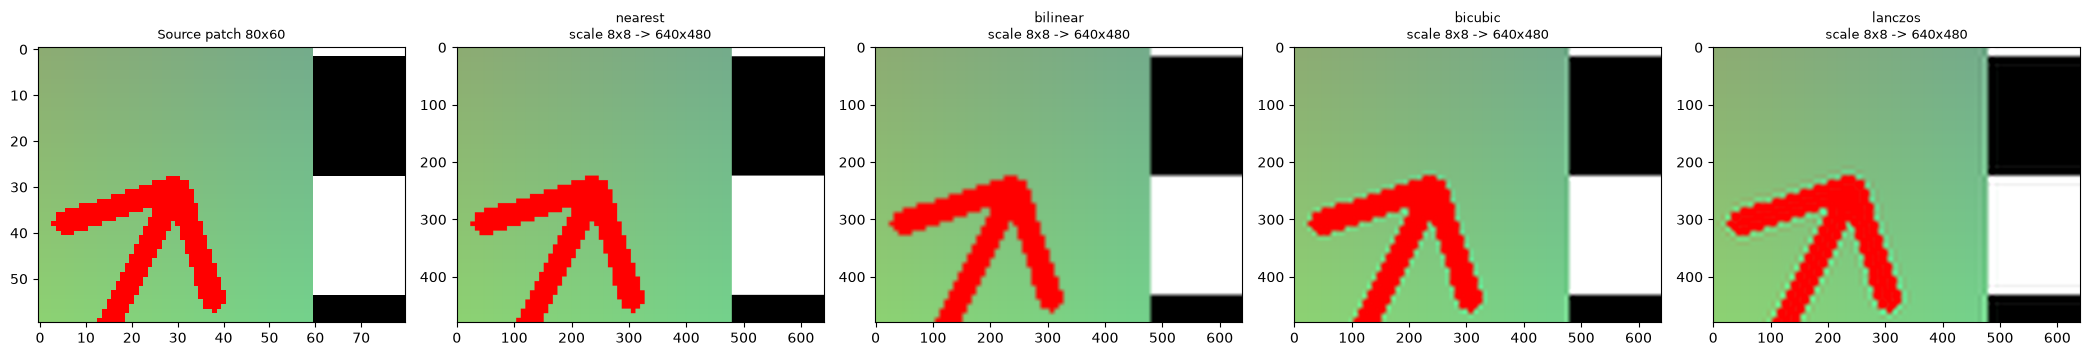

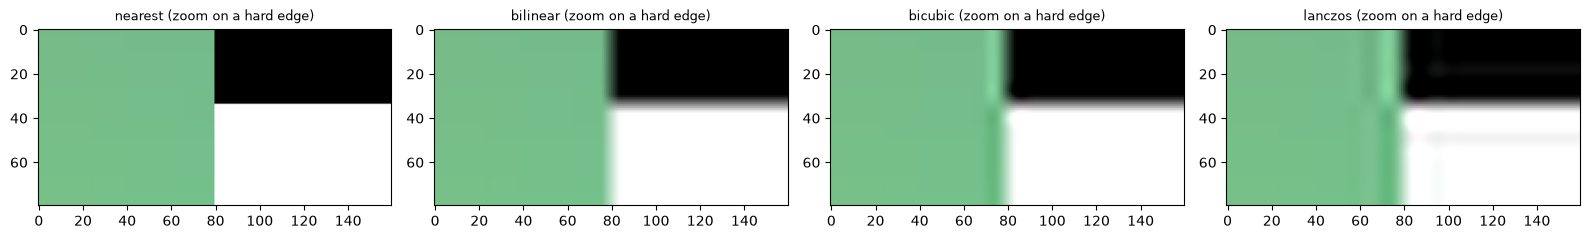

In [19]:
patch = transform(original, "crop", left=270, top=270, right=350, bottom=330)
print("patch shape:", patch.shape)
enl = {}
for name in INTERPOLATIONS:
    t0 = time.perf_counter()
    enl[name] = transform(patch, "scale", sx=8, sy=8, interpolation=name)
    dt = (time.perf_counter() - t0) * 1000
    save_result(f"interp_patch_x8_{name}", enl[name])
    print(f"{name:9s} -> {enl[name].shape[1]}x{enl[name].shape[0]}  ({dt:.2f} ms)")

fig, axes = plt.subplots(1, 5, figsize=(21, 3.9))
axes[0].imshow(patch); axes[0].set_title(f"Source patch {patch.shape[1]}x{patch.shape[0]}", fontsize=9)
for ax, name in zip(axes[1:], INTERPOLATIONS):
    ax.imshow(enl[name]); ax.set_title(f"{name}\nscale 8x8 -> {enl[name].shape[1]}x{enl[name].shape[0]}", fontsize=9)
plt.tight_layout(); fig.savefig(os.path.join(CMP_DIR, "5_interpolation_patch.png"), dpi=110, bbox_inches="tight"); plt.show()

# zoom into one hard edge (checkerboard boundary) so the differences are easy to see
zoom = {n: im[190:270, 400:560] for n, im in enl.items()}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (n, im) in zip(axes, zoom.items()):
    ax.imshow(im); ax.set_title(f"{n} (zoom on a hard edge)", fontsize=9)
plt.tight_layout(); fig.savefig(os.path.join(CMP_DIR, "5_interpolation_edge_zoom.png"), dpi=110, bbox_inches="tight"); plt.show()

In [20]:
# Objective numbers to back up the visual description
def gray(im): return cv2.cvtColor(im, cv2.COLOR_RGB2GRAY).astype(float)

# (a) blur: share of pixels in the checkerboard area (x >= 480 of the enlarged patch) that are
#     neither near-black nor near-white, i.e. lie on a soft transition between squares
# (b) ringing: largest brightness deviation from the nearest-neighbour result in the flat green
#     strip just left of the checkerboard edge (x 400..475, y 190..269) - nearest is perfectly flat there
flat_ref = gray(enl["nearest"])[190:270, 400:476]
print(f"{'method':9s} {'unique colours':>15s} {'soft-edge pixels (%)':>22s} {'ringing next to edge (grey levels)':>36s}")
for name, im in enl.items():
    g = gray(im)
    soft = ((g[:, 480:] > 25.5) & (g[:, 480:] < 229.5)).mean() * 100
    ring = np.abs(g[190:270, 400:476] - flat_ref).max()
    print(f"{name:9s} {len(np.unique(im.reshape(-1, 3), axis=0)):15d} {soft:22.2f} {ring:36.1f}")

method     unique colours   soft-edge pixels (%)   ringing next to edge (grey levels)
nearest               903                   0.00                                  0.0
bilinear             4206                   5.28                                  1.0
bicubic              4883                   5.06                                 22.0
lanczos              6152                   4.85                                 24.0


**Observations (interpolation) - from the figures and the table above:**
* **Nearest-neighbour** copies the closest pixel: every edge is a perfectly **hard staircase block**, it adds **no new colours** (fewest unique colours) and has **0 % soft-edge pixels**; it is also the fastest, but looks blocky.
* **Bilinear** averages the 4 nearest pixels: edges become **smooth but soft** - the checker borders turn into short gradients - and there is **no ringing** (the flat strip next to the edge differs by only ~1 grey level, which is just the edge blur).
* **Bicubic** uses a 4x4 neighbourhood: slightly **less soft than bilinear** (fewer soft-edge pixels) but introduces a visible **light halo** next to the hard edge (ringing about 22 grey levels).
* **Lanczos** uses an 8x8 neighbourhood: the **least soft** of the smooth methods; its ringing is similar in strength (about 24 grey levels) but the **ripples extend further** from hard black/white edges, and it was the slowest to compute.
* The differences between bilinear, bicubic and Lanczos are small in blur (about 5 % soft pixels each) but clear in ringing; nearest is the only method that keeps edges perfectly sharp (at the cost of blockiness).

## 6. Rejected inputs - at least one for every operation
Each case below is called **directly on `transform`** and must raise `TransformError` with a clear message (no crash, no silent default).

In [21]:
def print_table(headers, rows, widths):
    line = " | ".join(f"{h:<{w}}" for h, w in zip(headers, widths))
    print(line); print("-" * len(line))
    for r in rows:
        print(" | ".join(f"{str(c):<{w}}"[:w] if i < len(r) - 1 else str(c) for i, (c, w) in enumerate(zip(r, widths))))

bad_cases = [
    ("scale",     dict(sx=0, sy=1, interpolation="bilinear"),            "factor = 0"),
    ("scale",     dict(sx=-2, sy=1, interpolation="bilinear"),           "negative factor"),
    ("scale",     dict(sx=float("nan"), sy=1, interpolation="bilinear"), "NaN factor"),
    ("scale",     dict(sx=1, sy=float("inf"), interpolation="bilinear"), "infinite factor"),
    ("scale",     dict(sx="two", sy=1, interpolation="bilinear"),        "non-numeric factor"),
    ("scale",     dict(sx=1, sy=1, interpolation="cubic"),               "unsupported interpolation"),
    ("scale",     dict(sx=0.0001, sy=1, interpolation="nearest"),        "output width would be 0 px"),
    ("scale",     dict(sx=100, sy=100, interpolation="nearest"),         "output above size limit"),
    ("crop",      dict(left=100, top=0, right=100, bottom=50),           "left == right (empty)"),
    ("crop",      dict(left=0, top=0, right=601, bottom=50),             "right > width"),
    ("crop",      dict(left=-1, top=0, right=50, bottom=50),             "negative left"),
    ("crop",      dict(left=0, top=10.5, right=50, bottom=50),           "non-integer coordinate"),
    ("crop",      dict(left=0, top=60, right=50, bottom=40),             "bottom < top"),
    ("flip",      dict(direction="diagonal"),                            "unsupported direction"),
    ("flip",      dict(direction=1),                                     "non-string direction"),
    ("translate", dict(tx=float("inf"), ty=0),                           "infinite offset"),
    ("translate", dict(tx=0, ty=float("nan")),                           "NaN offset"),
    ("translate", dict(tx="ten", ty=0),                                  "non-numeric offset"),
    ("rotate",    dict(angle="abc", expand=False),                       "non-numeric angle"),
    ("rotate",    dict(angle=float("nan"), expand=False),                "NaN angle"),
    ("rotate",    dict(angle=float("-inf"), expand=True),                "infinite angle"),
    ("rotate",    dict(angle=15, expand="yes"),                          "invalid expand value"),
    ("warp",      dict(),                                                "unknown operation"),
    ("flip",      dict(),                                                "missing parameter"),
    ("rotate",    dict(angle=10),                                        "missing 'expand'"),
    ("translate", dict(tx=1, ty=2, extra=3),                             "unexpected parameter"),
]
rows, n_rejected = [], 0
for op, params, why in bad_cases:
    try:
        transform(original, op, **params); status, msg = "NOT REJECTED", ""
    except TransformError as e:
        status, msg, n_rejected = "REJECTED", str(e), n_rejected + 1
    rows.append((op, why, status, msg))
print_table(["operation", "bad input", "result", "error message"], rows, [10, 28, 12, 0])
print(f"\n{n_rejected} of {len(bad_cases)} invalid inputs were rejected with a TransformError (no crash).")

operation  | bad input                    | result       | error message
------------------------------------------------------------------------
scale      | factor = 0                   | REJECTED     | Scale factors must be greater than zero, got sx=0.0, sy=1.0.
scale      | negative factor              | REJECTED     | Scale factors must be greater than zero, got sx=-2.0, sy=1.0.
scale      | NaN factor                   | REJECTED     | 'sx' must be finite (not NaN/infinity), got nan.
scale      | infinite factor              | REJECTED     | 'sy' must be finite (not NaN/infinity), got inf.
scale      | non-numeric factor           | REJECTED     | 'sx' must be a number, got 'two' (str).
scale      | unsupported interpolation    | REJECTED     | Unsupported interpolation 'cubic'. Choose from: nearest, bilinear, bicubic, lanczos.
scale      | output width would be 0 px   | REJECTED     | Scaling by sx=0.0001, sy=1.0 would give an empty image (0x400); both sides must be >= 1 pixel.


**Boundary values that must be ACCEPTED** (zero and negative values are valid; the crop may touch the image edges):

In [22]:
ok_cases = [
    ("translate", dict(tx=0, ty=0),                         "zero offsets"),
    ("translate", dict(tx=-25, ty=0),                       "negative tx only"),
    ("rotate",    dict(angle=0, expand=False),               "zero angle"),
    ("rotate",    dict(angle=-90, expand=True),              "negative angle"),
    ("rotate",    dict(angle=725.5, expand=False),           "angle > 360"),
    ("crop",      dict(left=0, top=0, right=w0, bottom=h0),  "whole image (right=W, bottom=H)"),
    ("crop",      dict(left=w0-1, top=h0-1, right=w0, bottom=h0), "single pixel at bottom-right corner"),
    ("scale",     dict(sx=1, sy=1, interpolation="Nearest"), "factor 1, interpolation name any case"),
    ("scale",     dict(sx=0.01, sy=0.01, interpolation="bilinear"), "tiny factor but output 6x4 px (>= 1)"),
    ("flip",      dict(direction="BOTH"),                    "direction name any case"),
]
for op, params, why in ok_cases:
    res = transform(original, op, **params)
    print(f"ACCEPTED  {op:9s} {fmt_params(params):55s} -> {res.shape[1]}x{res.shape[0]}   ({why})")

ACCEPTED  translate tx=0, ty=0                                              -> 600x400   (zero offsets)
ACCEPTED  translate tx=-25, ty=0                                            -> 600x400   (negative tx only)
ACCEPTED  rotate    angle=0, expand=False                                   -> 600x400   (zero angle)
ACCEPTED  rotate    angle=-90, expand=True                                  -> 400x600   (negative angle)
ACCEPTED  rotate    angle=725.5, expand=False                               -> 600x400   (angle > 360)
ACCEPTED  crop      left=0, top=0, right=600, bottom=400                    -> 600x400   (whole image (right=W, bottom=H))
ACCEPTED  crop      left=599, top=399, right=600, bottom=400                -> 1x1   (single pixel at bottom-right corner)
ACCEPTED  scale     sx=1, sy=1, interpolation=Nearest                       -> 600x400   (factor 1, interpolation name any case)
ACCEPTED  scale     sx=0.01, sy=0.01, interpolation=bilinear                -> 6x4   (tiny factor but 

## 7. Identity checks
An identity case must return an image **identical** to the original (same shape and every pixel equal). `np.array_equal` gives the actual behaviour.

In [23]:
identity = [
    ("scale 1x1, nearest",   "scale",     dict(sx=1, sy=1, interpolation="nearest")),
    ("scale 1x1, bilinear",  "scale",     dict(sx=1, sy=1, interpolation="bilinear")),
    ("scale 1x1, bicubic",   "scale",     dict(sx=1, sy=1, interpolation="bicubic")),
    ("scale 1x1, lanczos",   "scale",     dict(sx=1, sy=1, interpolation="lanczos")),
    ("translate (0, 0)",     "translate", dict(tx=0, ty=0)),
    ("rotate 0, no expand",  "rotate",    dict(angle=0, expand=False)),
    ("rotate 0, expand",     "rotate",    dict(angle=0, expand=True)),
    ("rotate 360, no expand","rotate",    dict(angle=360, expand=False)),
    ("crop whole image",     "crop",      dict(left=0, top=0, right=w0, bottom=h0)),
]
rows = []
for name, op, params in identity:
    res = transform(original, op, **params)
    same_shape = res.shape == original.shape
    equal = same_shape and np.array_equal(res, original)
    maxdiff = int(np.abs(res.astype(int) - original.astype(int)).max()) if same_shape else -1
    rows.append((name, "same shape, all pixels equal",
                 f"shape {'same' if same_shape else 'DIFFERENT'}, max |diff| = {maxdiff}", "Pass" if equal else "Fail"))
# flipping twice is also an identity
twice = transform(transform(original, "flip", direction="both"), "flip", direction="both")
rows.append(("flip both, applied twice", "same shape, all pixels equal",
             f"max |diff| = {int(np.abs(twice.astype(int) - original.astype(int)).max())}",
             "Pass" if np.array_equal(twice, original) else "Fail"))
print_table(["case", "expected behaviour", "actual behaviour", "result"], rows, [24, 30, 36, 6])
print(f"\n{sum(r[3]=='Pass' for r in rows)} of {len(rows)} identity checks passed.")

case                     | expected behaviour             | actual behaviour                     | result
---------------------------------------------------------------------------------------------------------
scale 1x1, nearest       | same shape, all pixels equal   | shape same, max |diff| = 0           | Pass
scale 1x1, bilinear      | same shape, all pixels equal   | shape same, max |diff| = 0           | Pass
scale 1x1, bicubic       | same shape, all pixels equal   | shape same, max |diff| = 0           | Pass
scale 1x1, lanczos       | same shape, all pixels equal   | shape same, max |diff| = 0           | Pass
translate (0, 0)         | same shape, all pixels equal   | shape same, max |diff| = 0           | Pass
rotate 0, no expand      | same shape, all pixels equal   | shape same, max |diff| = 0           | Pass
rotate 0, expand         | same shape, all pixels equal   | shape same, max |diff| = 0           | Pass
rotate 360, no expand    | same shape, all pixels equal   | 

## 8. Brief explanations

In [24]:
x, y = 150, 130
print("Image coordinates vs array indexing")
print(f"  Point (x={x}, y={y}) is stored at original[{y}, {x}]  (row first, column second).")
print(f"  original[{y}, {x}] = {original[y, x]}")
print(f"  original.shape = {original.shape} = (height, width, channels), but cv2.resize / warpAffine take sizes as (width, height) = ({w0}, {h0}).")
print(f"  Valid index ranges: x in [0, {w0-1}], y in [0, {h0-1}]; crop's right/bottom may equal {w0}/{h0} because they are exclusive slice ends.")

Image coordinates vs array indexing
  Point (x=150, y=130) is stored at original[130, 150]  (row first, column second).
  original[130, 150] = [255 215   0]
  original.shape = (400, 600, 3) = (height, width, channels), but cv2.resize / warpAffine take sizes as (width, height) = (600, 400).
  Valid index ranges: x in [0, 599], y in [0, 399]; crop's right/bottom may equal 600/400 because they are exclusive slice ends.


**Image coordinates versus array indexing.** Image coordinates are written `(x, y)` with `x` = column (horizontal, to the right) and `y` = row (vertical, **downward**) from the top-left corner. NumPy arrays are indexed `[row, column]` = `[y, x]` and `shape` is `(height, width, channels)`. Mixing the two orders is the most common cause of transposed or wrongly cropped images, which is why `transform` takes `left/right` as x and `top/bottom` as y and slices `image[top:bottom, left:right]`.

**Aspect-ratio distortion.** The aspect ratio is `W/H`. Scaling with `sx == sy` keeps it (the 1.5 x 1.5 result is still 3:2, i.e. 1.500). With `sx != sy` the ratio changes to `(W*sx)/(H*sy)`: the 2.0 x 0.5 result is `1200x200`, ratio 6.0, so circles become wide ellipses and text is stretched.

**Rotation canvas expansion.** With `expand=False` the canvas stays `W x H`, so the corners of the rotated picture fall outside it and are **clipped**, while empty triangles of black background appear. With `expand=True` the canvas grows to `W' = W|cos a| + H|sin a|`, `H' = W|sin a| + H|cos a|` (e.g. +30 degrees gives `720x647` and -45 degrees gives `708x708`), so nothing is lost, at the price of a larger image with more black background. Rotation is about the image centre and a positive angle is counter-clockwise.

**Translation clipping.** Translation keeps the original canvas, so any pixel pushed beyond an edge is **lost (clipped)** and the opposite edge is **exposed** and filled with black. For `tx=+120, ty=+60` the left 120 columns and top 60 rows become background and the right 120 columns and bottom 60 rows of the original disappear. Shifting back would not restore the clipped content.

## 9. Final checks and saved results

In [25]:
# 1) the original image was never modified
print("Original unchanged:", np.array_equal(original, original_backup), "| writeable flag:", original.flags.writeable)

# 2) list of every saved transformed image
print(f"\n{len(RESULTS)} transformed images saved in '{OUT_DIR}/':")
print_table(["file name", "operation", "parameters", "output"],
            [(os.path.basename(p), op, par, size) for (_, op, par, size, p) in RESULTS], [52, 10, 62, 0])
print("\nComparison figures in", CMP_DIR + "/:", sorted(os.listdir(CMP_DIR)))

Original unchanged: True | writeable flag: False

21 transformed images saved in 'outputs/':
file name                                            | operation  | parameters                                                     | output
-------------------------------------------------------------------------------------------------------------------------------------------
interactive_scale.png                                | scale      | sx=1.5, sy=0.75, interpolation=bicubic                         | 900x300
interactive_crop.png                                 | crop       | left=100, top=50, right=400, bottom=250                        | 300x200
interactive_flip.png                                 | flip       | direction=both                                                 | 600x400
interactive_translate.png                            | translate  | tx=-80.0, ty=40.0                                              | 600x400
interactive_rotate.png                               | rotate  

### Rubric self-check (12 marks)
| Criterion | Evidence in this notebook | Marks |
|---|---|---|
| Reusable function and custom input | Single entry point `transform(image, operation, **params)` (section 2); operation and parameters entered through `input()` prompts via `run_interactive` and passed in (section 3); transformed images returned | 2 |
| Geometric operations | Scaling (enlarge, reduce, proportional, non-proportional), crop, 3 flips, translation (opposite directions), rotation (+/-, expand), affine matrices verified (sections 4.1-4.6) | 4 |
| Input validation | Image validation (section 1); parameter validation inside `transform` and in the text parsers; 26 rejected cases, boundary values accepted, identity checks (sections 6-7) | 3 |
| Comparisons and observations | 4-method interpolation comparison with numbers and description (section 5); labelled outputs with dimensions; clipping, aspect-ratio, expansion and coordinate explanations (sections 4, 8) | 2 |
| Repository submission | `README.md`, notebook, `transforms.py`, `input/`, `outputs/`, `requirements.txt`, `.gitignore`; notebook fully executed with visible outputs | 1 |